## Аналитическое решение

<img src="./geom.png" width="700" />

Выберем случайную точку внутри правильного n-угольника.

Заметим, что она точно попадет в один из равнобедренных треугольников, построенных на одной из сторон и центре описанной окружности (на изображении это треугольник OHJ) -- назовем этот треугольник долей

Для этой точки самая близкая сторона -- как раз основание доли (на изображении -- HJ). Например, доказательство для соседних сторон многоугольника -- докажем, что точки строго внутри OHJ ближе к HJ, чем к FH: OH является биссектрисой угла FHJ по симметрии, а значит на ней лежат точки, равноудаленные от сторон FH и HJ. То есть справа от OH точки ближе именно к HJ.

Для других сторон многоугольника очевидно.

Нас интересует, когда минимальное расстояние от точки до какой-либо стороны многоугольника меньше, чем минимальное расстояние от точки до какой-либо его диагонали. (\*) 

Заметим, что диагонали, которые на изображении помечены пунктирными линиями, наиболее близко расположены к стороне многоугольника. Если точка лежит над ними, то она не удовлетворяет (\*). Если она лежит под ними, и при этом над биссектрисами углов при основании (а они равноудалены от этих диагоналей и стороны многоугольника), то она все еще ближе к диагоналям. То есть только зеленая зона под ними удовлетворяет (\*). Найдем отношение зеленой площади к площади доли.

1) $\triangle FHJ \text{ р/б, } \angle FHJ = 180^\circ \frac{n - 2}{n} = \pi \frac{n - 2}{n}$ (по свойству правильного многоугольника)
2) $\angle JFH = \angle HJF = \frac{\pi - \angle FHJ}{2} = \frac{\pi - \pi \frac{n - 2}{n}}{2} = \frac{\pi}{n}$
3) $\angle HJQ = \frac{\angle HJF}{2} = \frac{\pi}{2n}$
4) $\frac{S_{HQJ}}{S_{HOJ}} = \frac{S_{QRJ}}{S_{ORJ}} = P_{n}$
5) $\angle ROJ = \frac{\angle HOJ}{2} = \frac{\pi}{n}$
6) $\triangle ORJ \sim \triangle PRJ$ ($ \angle ROJ = \angle PJR = \frac{\pi}{n} $ + есть прямой угол)
7) $k_{подобия} = \frac{RJ}{OR} = \frac{OJ sin(\frac{\pi}{n})}{OJ cos(\frac{\pi}{n})} = tg(\frac{\pi}{n})$
8) $\frac{S_{PJR}}{S_{ORJ}} = k_{подобия}^2 = (tg(\frac{\pi}{n}))^2$
9) $\frac{S_{QJR}}{S_{PJR}} = \frac{QR}{PR} = \frac{tg(\frac{\pi}{2n})}{tg(\frac{\pi}{n})}$
10) $\frac{S_{QJR}}{S_{ORJ}} = \frac{S_{PJR}}{S_{ORJ}} \frac{S_{QJR}}{S_{PJR}} = \frac{(sin(\frac{\pi}{n}))^{2} tg(\frac{\pi}{2n})}{(cos(\frac{\pi}{n}))^2 tg(\frac{\pi}{n})} = \frac{(sin(\frac{\pi}{n}))^2 sin(\frac{\pi}{2n}) cos(\frac{\pi}{n})}{(cos(\frac{\pi}{n}))^2 sin(\frac{\pi}{n}) cos(\frac{\pi}{2n})} = \frac{2 (sin(\frac{\pi}{2n}))^2 cos(\frac{\pi}{2n})}{cos(\frac{\pi}{n}) cos(\frac{\pi}{2n})} = \frac{1 - cos(\frac{\pi}{n})}{cos(\frac{\pi}{n})} = \frac{1}{cos(\frac{\pi}{n})} - 1 = sec(\frac{\pi}{n}) - 1 = P_{n}$


Разложим $P_{n}$ в ряд Тейлора (около 0)

$$ sec(x) = \sum_{k=0}^{\infty} \frac{(-1)^{k} E_{2k}}{(2k)!}x^{2k} = 1 + \frac{x^2}{2} + \frac{5x^4}{24} + ...$$

Где $E_{k}$ -- числа Эйлера. При $n \to \infty$ имеем $\frac{\pi}{n} \to 0$, поэтому

$$P_{n} = sec(\frac{\pi}{n}) - 1 = n^{-2} \frac{\pi^2}{2} + n^{-4} \frac{5\pi^4}{24} + ... = \frac{\pi^2}{2} n^{-2} (1 + n^{-2} \frac{5\pi^2}{12} + ...) = \frac{\pi^2}{2} n^{-2}(1 + o(1)) \text{ при } n \to \infty$$

Поэтому подберем

$$C = \frac{\pi^2}{2} \text{, } a = -2$$

Чтобы

$$P_{n} = C n^{a}(1 + o(1)) \text{ при } n \to \infty$$

## Эмперическое решение

In [33]:
!pip3 install numpy matplotlib tqdm

  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
Using cached tqdm-4.70.1-py3-none-any.whl (80 kB)


In [1]:
# я редактирую geometry.py параллельно
# он должен загружаться заново
import importlib

import numpy as np
import geometry as geom
import matplotlib.pyplot as plt
import tqdm

importlib.reload(geom)

<module 'geometry' from '/home/ilya/Desktop/teorver_laba/2/geometry.py'>

In [2]:
np.random.seed(66)

def empirical_prob(n, n_iter=100, radius=10):
    success = 0

    regular_polygon = geom.RegularPolygon(n, radius)

    for i in range(n_iter):
        random_point_inside = regular_polygon.random_inner_point()
        dist_from_diag = regular_polygon.closest_distance_from_diagonal(random_point_inside)
        dist_from_side = regular_polygon.closest_distance_from_side(random_point_inside)

        if np.isnan(dist_from_diag) or dist_from_side < dist_from_diag:
            success += 1

    return success / n_iter

def theoretical_prob(n):
    return 1 / np.cos(np.pi / n) - 1

def plot_probs(ns, n_iter=10, radius=10):
    theo = [theoretical_prob(n) for n in ns]
    empr = [empirical_prob(n, n_iter=n_iter, radius=radius) for n in tqdm.tqdm(ns)]

    plt.plot(ns, theo, label="theoretical", color="blue")
    plt.plot(ns, empr, label="empirical", color="red")
    plt.xlabel("n")
    plt.ylabel("probability")
    plt.legend()
    plt.show()

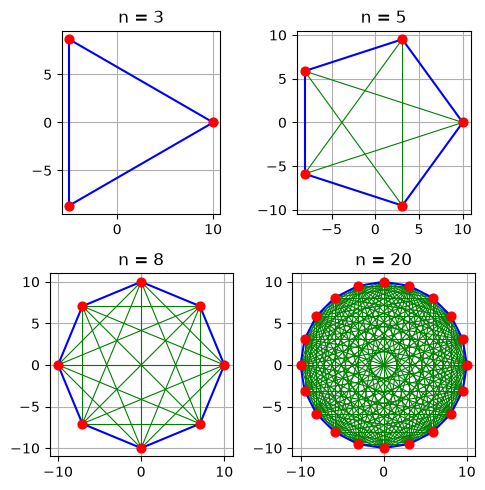

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(5, 5))

for ax, n in zip(axes.flat, [3, 5, 8, 20]):
    poly = geom.RegularPolygon(n, 10)
    poly.draw(ax)
    ax.set_title(f"n = {n}")

plt.tight_layout()
plt.show()

100%|██████████| 47/47 [00:18<00:00,  2.58it/s]


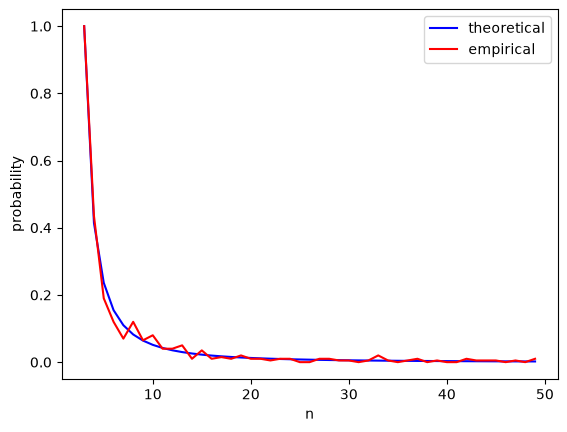

In [4]:
MAX_N = 50

plot_probs(range(3, MAX_N), n_iter=200, radius=100)

In [5]:
# Как видим, графики лежат близко